# StayScope: Airbnb Data Analysis (New York City, 2019)

This notebook combines the StayScope analysis workflow into one ordered, reproducible notebook:

1. Dataset inspection
2. Data cleaning
3. Exploratory Data Analysis (EDA)
4. Price outlier analysis
5. K-Means clustering
6. Listing-title text mining (single words and two-word phrases)
7. Neighbourhood and room-type pattern analysis

**Input required:** `data/AB_NYC_2019.csv` in the StayScope project folder.

Keep this notebook in the project's `notebooks` folder. The notebook writes the cleaned dataset to `data/cleaned_airbnb.csv` and analysis tables and charts to `outputs/`.

**Before submission:** open this notebook from the StayScope project, then choose **Kernel → Restart Kernel and Run All Cells**. Confirm that every cell finishes without an error and that the output folder contains the generated files.

## 1. Setup and project paths

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Resolve project root when Jupyter starts in either the root or notebooks folder.
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name.lower() == "notebooks":
    BASE_DIR = CURRENT_DIR.parent
elif (CURRENT_DIR / "data").exists():
    BASE_DIR = CURRENT_DIR
elif (CURRENT_DIR.parent / "data").exists():
    BASE_DIR = CURRENT_DIR.parent
else:
    BASE_DIR = CURRENT_DIR

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = DATA_DIR / "AB_NYC_2019.csv"
CLEAN_DATA_PATH = DATA_DIR / "cleaned_airbnb.csv"

print("Project directory:", BASE_DIR)
print("Raw dataset exists:", RAW_DATA_PATH.exists())
if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(f"Place AB_NYC_2019.csv in: {DATA_DIR}")


Project directory: C:\Users\saksh\StayScope
Raw dataset exists: True


## 2. Dataset inspection

In [2]:
df_raw = pd.read_csv(RAW_DATA_PATH)

print("========== STAYSCOPE DATA INSPECTION ==========")
print("Dataset shape:", df_raw.shape)
print("\nFirst 5 records:")
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nDataset information:")
df_raw.info()
print("\nMissing values:")
display(df_raw.isnull().sum().to_frame("missing_values"))


========== STAYSCOPE DATA INSPECTION ==========
Dataset shape: (48895, 16)

First 5 records:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64


,missing_values
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


## 3. Data cleaning

Following `clean_data.py`: remove duplicate rows, fill missing listing and host names, fill missing monthly reviews with zero, parse review dates, remove non-positive prices, and retain valid latitude/longitude values.


In [3]:
df = pd.read_csv(RAW_DATA_PATH)
print("Original dataset shape:", df.shape)

df.drop_duplicates(inplace=True)
df["name"] = df["name"].fillna("Unknown Listing")
df["host_name"] = df["host_name"].fillna("Unknown Host")
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
df = df[df["price"] > 0].copy()
df = df[
    df["latitude"].between(-90, 90) &
    df["longitude"].between(-180, 180)
].copy()

df.to_csv(CLEAN_DATA_PATH, index=False)
print("Cleaning completed successfully!")
print("Cleaned dataset shape:", df.shape)
print("\nRemaining missing values:")
display(df.isnull().sum().to_frame("missing_values"))
print("Cleaned dataset saved at:", CLEAN_DATA_PATH)


Original dataset shape: (48895, 16)
Cleaning completed successfully!
Cleaned dataset shape: (48884, 16)

Remaining missing values:


,missing_values
id,0
name,0
host_id,0
host_name,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


Cleaned dataset saved at: C:\Users\saksh\StayScope\data\cleaned_airbnb.csv


## 4. Exploratory Data Analysis (EDA)

In [4]:
print("Dataset overview:")
display(df.describe(include="all").transpose())

print("Average Airbnb price:", round(df["price"].mean(), 2))
print("\nRoom type distribution:")
display(df["room_type"].value_counts().to_frame("listing_count"))

print("\nAverage price by room type:")
display(df.groupby("room_type")["price"].mean().round(2).to_frame("average_price"))

print("\nTop 10 neighbourhoods:")
display(df["neighbourhood"].value_counts().head(10).to_frame("listing_count"))

print("\nAverage price by neighbourhood group:")
display(
    df.groupby("neighbourhood_group")["price"]
      .mean().sort_values(ascending=False).round(2)
      .to_frame("average_price")
)


Dataset overview:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,48884.0,NaN,NaN,NaN,19016793.406677,2539.0,9470547.5,19675740.5,29152966.75,36487245.0,10984315.037942
name,48884,47895,Hillside Hotel,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,48884.0,NaN,NaN,NaN,67622034.561124,2438.0,7817310.25,30792573.5,107434423.0,274321313.0,78616662.300425
host_name,48884,11451,Michael,417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_group,48884,5,Manhattan,21660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood,48884,221,Williamsburg,3919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,48884.0,NaN,NaN,NaN,40.728953,40.49979,40.6901,40.72308,40.76312,40.91306,0.054532
longitude,48884.0,NaN,NaN,NaN,-73.952176,-74.24442,-73.98308,-73.955685,-73.93629,-73.71299,0.046159
room_type,48884,3,Entire home/apt,25407,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,48884.0,NaN,NaN,NaN,152.755053,10.0,69.0,106.0,175.0,10000.0,240.17026


Average Airbnb price: 152.76

Room type distribution:


,listing_count
room_type,
Entire home/apt,25407
Private room,22319
Shared room,1158



Average price by room type:


,average_price
room_type,
Entire home/apt,211.81
Private room,89.81
Shared room,70.25



Top 10 neighbourhoods:


,listing_count
neighbourhood,
Williamsburg,3919
Bedford-Stuyvesant,3710
Harlem,2658
Bushwick,2462
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564



Average price by neighbourhood group:


,average_price
neighbourhood_group,
Manhattan,196.88
Brooklyn,124.44
Staten Island,114.81
Queens,99.52
Bronx,87.58


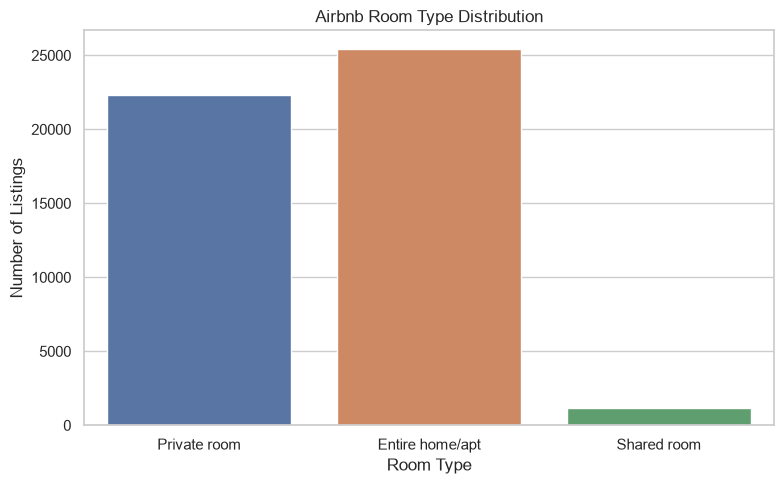

In [5]:
# Room type distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="room_type", hue="room_type", legend=False)
plt.title("Airbnb Room Type Distribution")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "room_type_distribution.png", dpi=150)
plt.show()


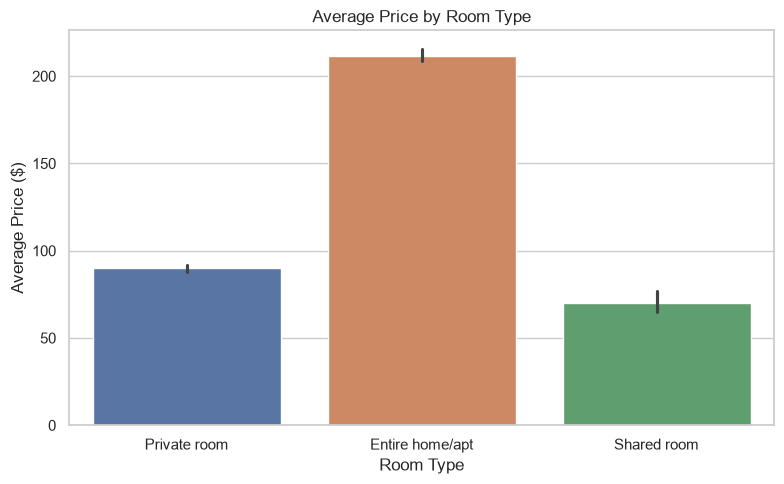

In [6]:
# Average price by room type
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="room_type", y="price", hue="room_type", legend=False)
plt.title("Average Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Price ($)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "average_price_by_room_type.png", dpi=150)
plt.show()


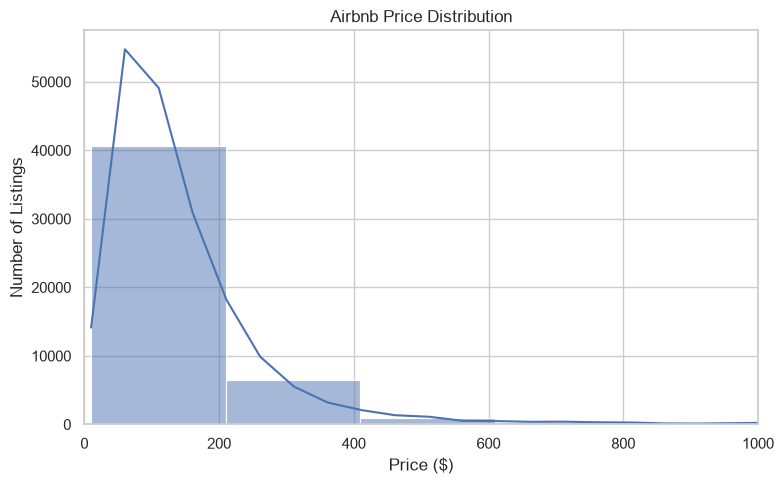

In [7]:
# Price distribution; x-axis is limited to $1,000 for readability
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=50, kde=True)
plt.title("Airbnb Price Distribution")
plt.xlabel("Price ($)")
plt.ylabel("Number of Listings")
plt.xlim(0, 1000)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_distribution.png", dpi=150)
plt.show()


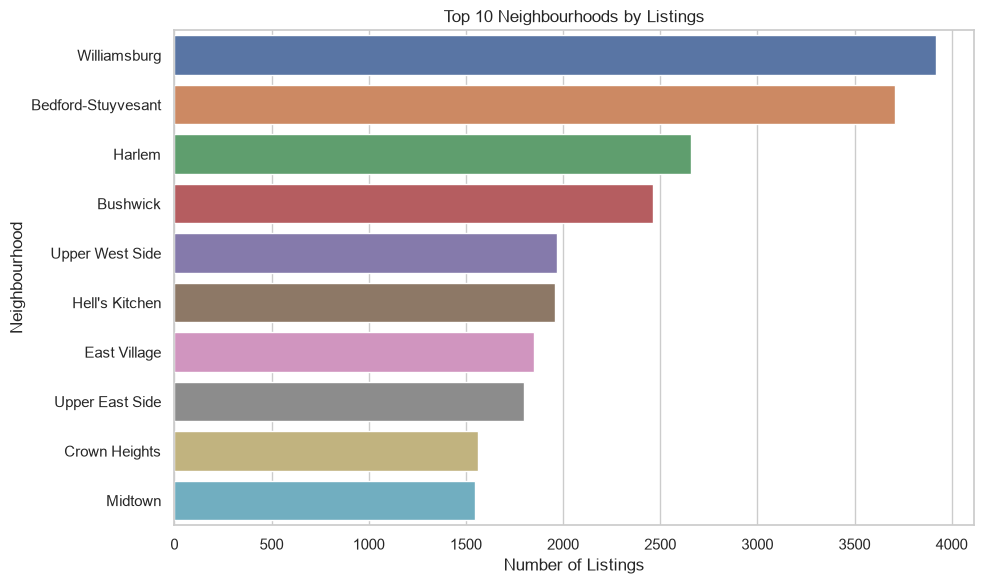

In [8]:
# Top 10 neighbourhoods by listing count
top_neighbourhoods = df["neighbourhood"].value_counts().head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_neighbourhoods.values,
    y=top_neighbourhoods.index,
    hue=top_neighbourhoods.index,
    legend=False
)
plt.title("Top 10 Neighbourhoods by Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_neighbourhoods.png", dpi=150)
plt.show()


## 5. Price outlier analysis

The Interquartile Range (IQR) method identifies prices below the lower limit or above the upper limit. Outliers are reported, not removed.


In [9]:
print("Price statistics:")
display(df["price"].describe().to_frame("price"))

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
].copy()
print("Total price outliers:", len(outliers))

print("\nTop 10 most expensive listings:")
display(df.nlargest(10, "price")[
    ["name", "neighbourhood_group", "room_type", "price"]
])


Price statistics:


,price
count,48884.000000
mean,152.755053
std,240.170260
min,10.000000
25%,69.000000
50%,106.000000
75%,175.000000
max,10000.000000


Lower limit: -90.0
Upper limit: 334.0
Total price outliers: 2972

Top 10 most expensive listings:


,name,neighbourhood_group,room_type,price
9151,Furnished room in Astoria apartment,Queens,Private room,10000
17692,Luxury 1 bedroom apt. -stunning Manhattan views,Brooklyn,Entire home/apt,10000
29238,1-BR Lincoln Center,Manhattan,Entire home/apt,10000
6530,Spanish Harlem Apt,Manhattan,Entire home/apt,9999
12342,"Quiet, Clean, Lit @ LES & Chinatown",Manhattan,Private room,9999
40433,2br - The Heart of NYC: Manhattans Lower East ...,Manhattan,Entire home/apt,9999
30268,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,Manhattan,Entire home/apt,8500
4377,Film Location,Brooklyn,Entire home/apt,8000
29662,East 72nd Townhouse by (Hidden by Airbnb),Manhattan,Entire home/apt,7703
42523,70' Luxury MotorYacht on the Hudson,Manhattan,Entire home/apt,7500


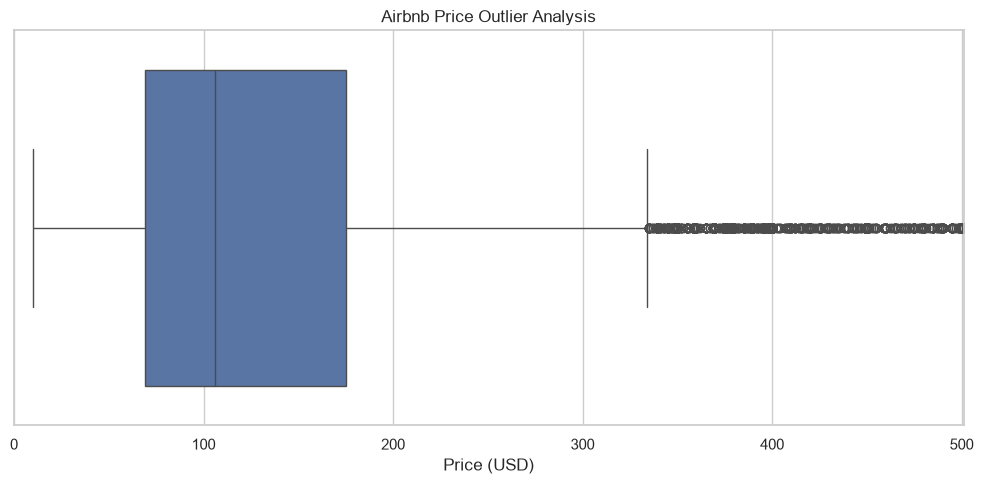

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["price"])
plt.title("Airbnb Price Outlier Analysis")
plt.xlabel("Price (USD)")
plt.xlim(0, upper_limit * 1.5)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_outliers.png", dpi=150)
plt.show()


## 6. K-Means clustering

The supplied script uses five features: price, minimum nights, number of reviews, reviews per month, and availability over 365 days. Four skewed features are log-transformed, all features are standardized, and K-Means is fitted with four clusters.


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "availability_365"
]

X = df[features].copy()
for column in ["price", "minimum_nights", "number_of_reviews", "reviews_per_month"]:
    X[column] = np.log1p(X[column])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

score = silhouette_score(
    X_scaled,
    df["cluster"],
    sample_size=min(5000, len(df)),
    random_state=42
)
print("Silhouette score:", round(score, 3))

print("\nCluster summary:")
display(df.groupby("cluster")[features].mean().round(2))

print("\nListings per cluster:")
display(df["cluster"].value_counts().sort_index().to_frame("listing_count"))

clustered_path = OUTPUT_DIR / "clustered_airbnb.csv"
df.to_csv(clustered_path, index=False)
print("Clustered dataset saved at:", clustered_path)


Silhouette score: 0.307

Cluster summary:


,price,minimum_nights,number_of_reviews,reviews_per_month,availability_365
cluster,,,,,
0,235.14,2.66,13.14,0.80,295.59
1,139.99,3.27,4.25,0.25,16.89
2,178.89,36.28,6.68,0.26,210.81
3,118.83,2.41,66.75,2.98,129.20



Listings per cluster:


,listing_count
cluster,
0,7116
1,22086
2,6052
3,13630


Clustered dataset saved at: C:\Users\saksh\StayScope\outputs\clustered_airbnb.csv


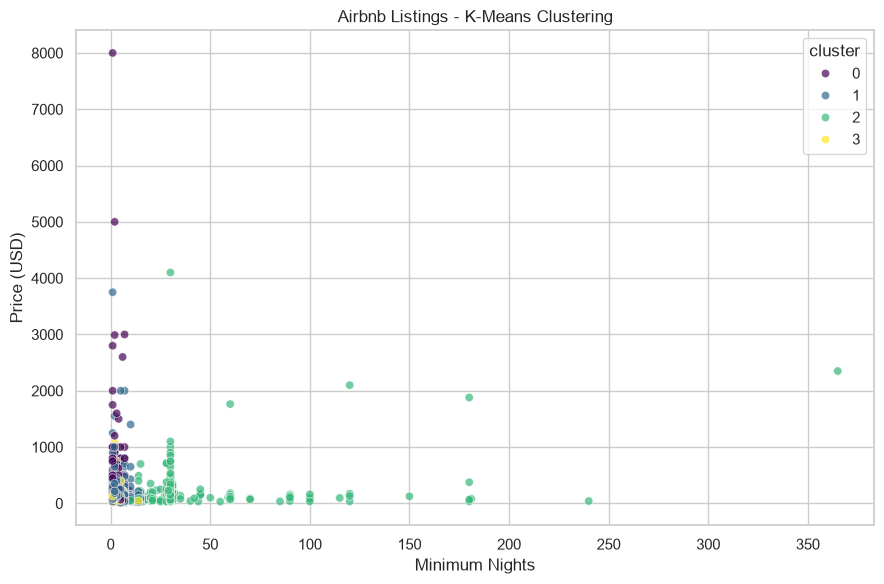

In [12]:
plot_sample = df.sample(min(5000, len(df)), random_state=42)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_sample,
    x="minimum_nights",
    y="price",
    hue="cluster",
    palette="viridis",
    alpha=0.7
)
plt.title("Airbnb Listings - K-Means Clustering")
plt.xlabel("Minimum Nights")
plt.ylabel("Price (USD)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_clusters.png", dpi=150)
plt.show()


## 7. Listing-title text mining

In [13]:
from sklearn.feature_extraction.text import CountVectorizer

titles = df["name"].fillna("").astype(str)
titles = titles[titles.str.strip() != ""]

# Most frequent individual words
word_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 1),
    max_features=20
)
word_matrix = word_vectorizer.fit_transform(titles)
word_results = pd.DataFrame({
    "term": word_vectorizer.get_feature_names_out(),
    "frequency": word_matrix.sum(axis=0).A1
}).sort_values("frequency", ascending=False)

print("Top 20 frequently used words:")
display(word_results)

# Most frequent two-word phrases
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20
)
bigram_matrix = bigram_vectorizer.fit_transform(titles)
bigram_results = pd.DataFrame({
    "term": bigram_vectorizer.get_feature_names_out(),
    "frequency": bigram_matrix.sum(axis=0).A1
}).sort_values("frequency", ascending=False)

print("Top 20 frequently used two-word phrases:")
display(bigram_results)

word_results.to_csv(OUTPUT_DIR / "frequent_words.csv", index=False)
bigram_results.to_csv(OUTPUT_DIR / "frequent_bigrams.csv", index=False)


Top 20 frequently used words:


,term,frequency
14,room,10276
3,bedroom,8202
13,private,7408
0,apartment,6759
5,cozy,5096
1,apt,4740
4,brooklyn,4173
16,studio,4106
15,spacious,3794
9,manhattan,3592


Top 20 frequently used two-word phrases:


,term,frequency
11,private room,2893
3,central park,1355
7,east village,1321
10,private bedroom,1059
1,bedroom apartment,902
6,cozy room,870
17,upper east,694
16,times square,670
19,west village,641
8,new york,622


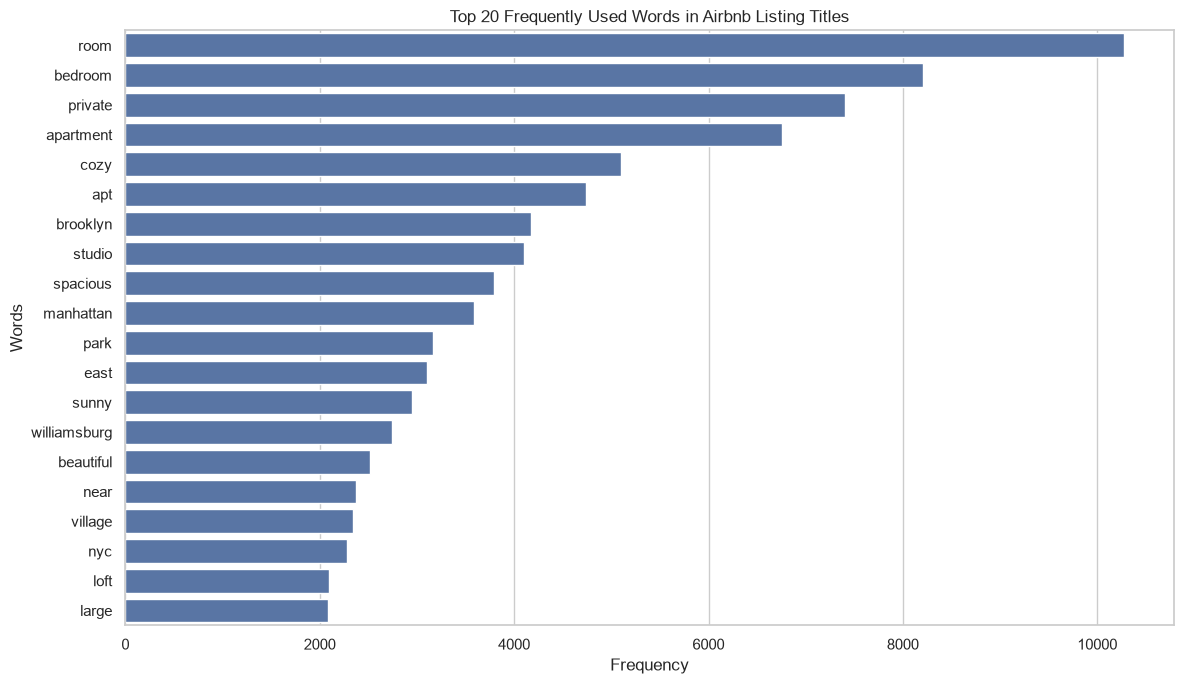

In [14]:
plt.figure(figsize=(12, 7))
sns.barplot(data=word_results, x="frequency", y="term")
plt.title("Top 20 Frequently Used Words in Airbnb Listing Titles")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "frequent_words.png", dpi=150)
plt.show()


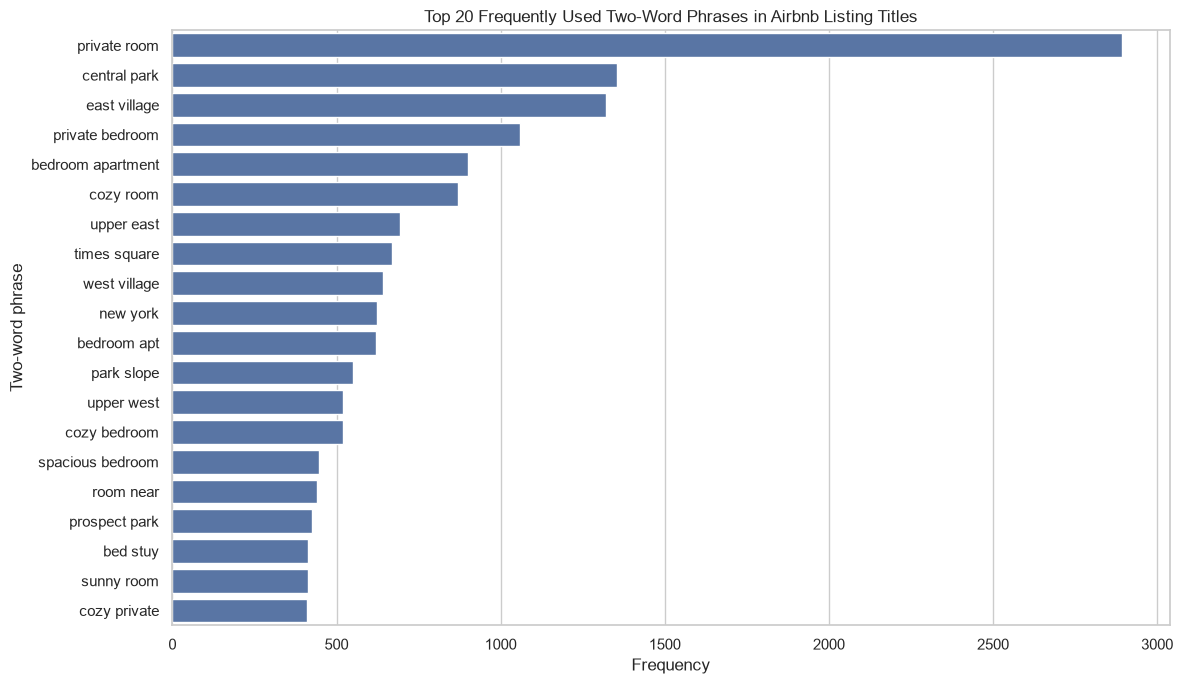

In [15]:
# Visualize the most frequent two-word phrases
plt.figure(figsize=(12, 7))
sns.barplot(data=bigram_results, x="frequency", y="term")
plt.title("Top 20 Frequently Used Two-Word Phrases in Airbnb Listing Titles")
plt.xlabel("Frequency")
plt.ylabel("Two-word phrase")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "frequent_bigrams.png", dpi=150)
plt.show()

## 8. Neighbourhood and room-type pattern analysis

In [16]:
# Listings in each neighbourhood group
neighbourhood_counts = df["neighbourhood_group"].value_counts()
print("Listings by neighbourhood group:")
display(neighbourhood_counts.to_frame("listing_count"))

# Room type distribution by neighbourhood group
room_patterns = pd.crosstab(df["neighbourhood_group"], df["room_type"])
print("Room type distribution by neighbourhood group:")
display(room_patterns)

# Average price by neighbourhood group and room type
price_patterns = df.pivot_table(
    values="price",
    index="neighbourhood_group",
    columns="room_type",
    aggfunc="mean"
).round(2)
print("Average price by neighbourhood group and room type:")
display(price_patterns)

neighbourhood_counts.to_csv(OUTPUT_DIR / "neighbourhood_counts.csv")
room_patterns.to_csv(OUTPUT_DIR / "room_type_patterns.csv")
price_patterns.to_csv(OUTPUT_DIR / "price_patterns.csv")


Listings by neighbourhood group:


,listing_count
neighbourhood_group,
Manhattan,21660
Brooklyn,20095
Queens,5666
Bronx,1090
Staten Island,373


Room type distribution by neighbourhood group:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,379,651,60
Brooklyn,9558,10126,411
Manhattan,13198,7982,480
Queens,2096,3372,198
Staten Island,176,188,9


Average price by neighbourhood group and room type:


room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,127.51,66.89,59.80
Brooklyn,178.35,76.55,50.77
Manhattan,249.26,116.78,88.98
Queens,147.05,71.76,69.02
Staten Island,173.85,62.29,57.44


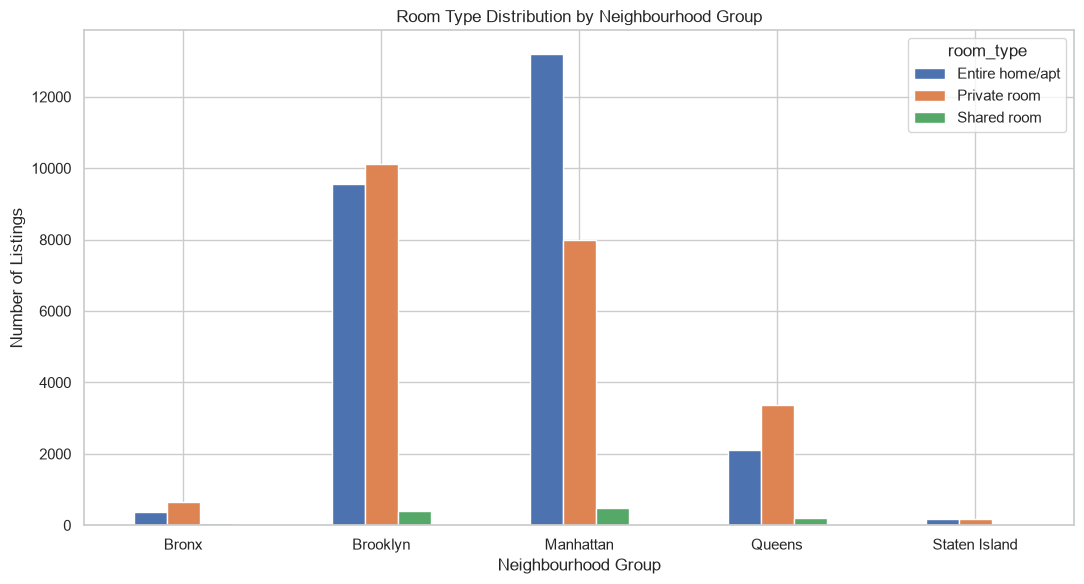

In [17]:
room_patterns.plot(kind="bar", figsize=(11, 6))
plt.title("Room Type Distribution by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "room_type_patterns.png", dpi=150)
plt.show()


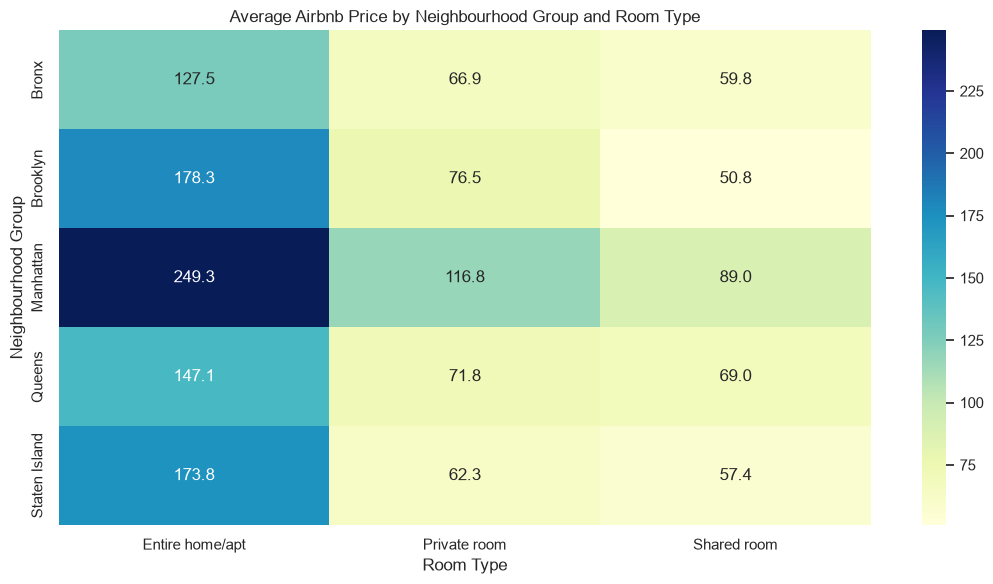

In [18]:
plt.figure(figsize=(11, 6))
sns.heatmap(price_patterns, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Airbnb Price by Neighbourhood Group and Room Type")
plt.xlabel("Room Type")
plt.ylabel("Neighbourhood Group")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "price_patterns_heatmap.png", dpi=150)
plt.show()


## 9. Final output check

Expected outputs include the cleaned dataset, clustered dataset, summary CSV files, and analysis charts, including both frequent-word and frequent-bigram charts.

Run the notebook from top to bottom using **Kernel → Restart Kernel and Run All Cells** before submission. A notebook with empty execution counts and no saved outputs has not yet demonstrated a successful full run.

In [19]:
print("========== STAYSCOPE ANALYSIS COMPLETE ==========")
print("Cleaned dataset:", CLEAN_DATA_PATH)
print("\nFiles generated in outputs:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name} ({file_path.stat().st_size:,} bytes)")


========== STAYSCOPE ANALYSIS COMPLETE ==========
Cleaned dataset: C:\Users\saksh\StayScope\data\cleaned_airbnb.csv

Files generated in outputs:
average_price_by_room_type.png (32,130 bytes)
clustered_airbnb.csv (7,253,316 bytes)
frequent_bigrams.csv (370 bytes)
frequent_bigrams.png (87,373 bytes)
frequent_words.csv (279 bytes)
frequent_words.png (64,464 bytes)
kmeans_clusters.png (76,419 bytes)
neighbourhood_counts.csv (104 bytes)
price_distribution.png (45,259 bytes)
price_outliers.png (24,226 bytes)
price_patterns.csv (208 bytes)
price_patterns_heatmap.png (80,728 bytes)
room_type_distribution.png (32,066 bytes)
room_type_patterns.csv (178 bytes)
room_type_patterns.png (51,663 bytes)
source_code_review.txt (14,788 bytes)
top_neighbourhoods.png (58,309 bytes)
